# Імпорт бібліотек та фіксація зерна генерації #

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.datasets import make_regression, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# Задаємо номер у журналі (змініть на свій, наприклад, 7)
JOURNAL_NUMBER = 7
RANDOM_STATE = JOURNAL_NUMBER

# Розрахунок параметрів за завданням
N_SAMPLES = 1000 * JOURNAL_NUMBER
N_CLASSES = JOURNAL_NUMBER + 2

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
sns.set(style='whitegrid')

print(f"Варіант (номер у журналі): {JOURNAL_NUMBER}")
print(f"Кількість зразків: {N_SAMPLES}")
print(f"Кількість класів (класифікація): {N_CLASSES}")

Варіант (номер у журналі): 7
Кількість зразків: 7000
Кількість класів (класифікація): 9


# Генерація даних для регресії та класифікації #

In [2]:
# 1. Генерація даних для регресії
X_reg, y_reg = make_regression(
    n_samples=N_SAMPLES,
    n_features=5,
    n_informative=5,
    noise=15.0,
    random_state=RANDOM_STATE
)

# 2. Генерація даних для класифікації
X_clf, y_clf = make_classification(
    n_samples=N_SAMPLES,
    n_features=12,
    n_informative=10,
    n_redundant=2,
    n_classes=N_CLASSES,
    n_clusters_per_class=1,
    class_sep=1.5,
    random_state=RANDOM_STATE
)

print("Форма даних регресії:", X_reg.shape, y_reg.shape)
print("Форма даних класифікації:", X_clf.shape, y_clf.shape)

Форма даних регресії: (7000, 5) (7000,)
Форма даних класифікації: (7000, 12) (7000,)


# Візуалізація згенерованих даних #

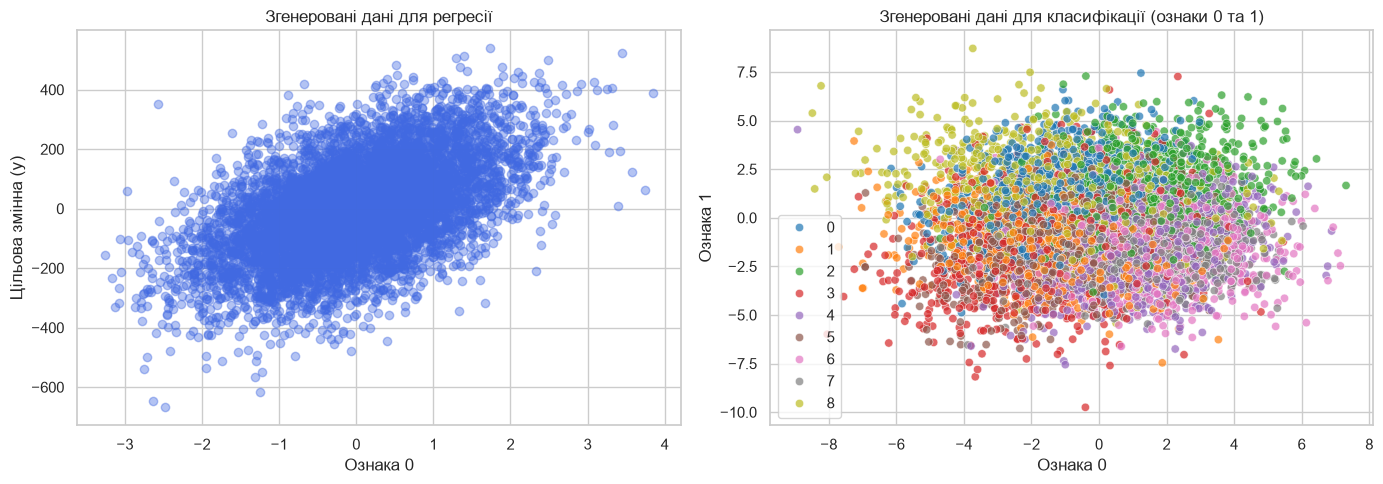

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Регресія (беремо першу ознаку для осі X)
axes[0].scatter(X_reg[:, 0], y_reg, alpha=0.4, color='royalblue')
axes[0].set_title("Згенеровані дані для регресії")
axes[0].set_xlabel("Ознака 0")
axes[0].set_ylabel("Цільова змінна (y)")

# Класифікація (беремо перші дві ознаки)
sns.scatterplot(
    x=X_clf[:, 0], y=X_clf[:, 1], hue=y_clf, 
    palette=sns.color_palette('tab10', N_CLASSES), 
    ax=axes[1], alpha=0.7, legend='full'
)
axes[1].set_title("Згенеровані дані для класифікації (ознаки 0 та 1)")
axes[1].set_xlabel("Ознака 0")
axes[1].set_ylabel("Ознака 1")

plt.tight_layout()
plt.show()

# Підготовка даних та побудова моделі РЕГРЕСІЇ #

In [4]:
# Розподіл на train/test та масштабування
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

scaler_reg = StandardScaler()
X_train_reg_s = scaler_reg.fit_transform(X_train_reg)
X_test_reg_s = scaler_reg.transform(X_test_reg)

# Архітектура нейронної мережі для регресії
model_reg = Sequential([
    Input(shape=(5,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)  # 1 нейрон без активації для неперервного виходу
])

model_reg.compile(optimizer=Adam(learning_rate=0.01), loss='mean_squared_error')
model_reg.summary()

# Навчання моделі
history_reg = model_reg.fit(X_train_reg_s, y_train_reg,
    epochs=50, batch_size=32,
    validation_split=0.2, verbose=0)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,497 (9.75 KB)

 Trainable params: 2,497 (9.75 KB)

 Non-trainable params: 0 (0.00 B)

# Оцінка та візуалізація результатів РЕГРЕСІЇ #

Mean Squared Error (MSE): 241.0627
Коефіцієнт детермінації (R²): 0.9910


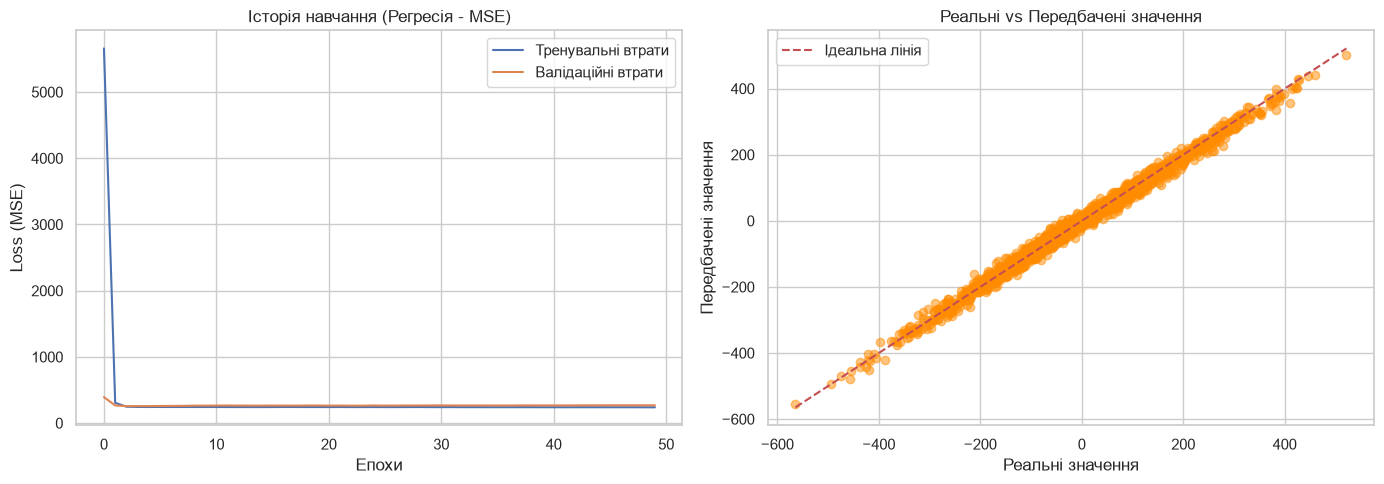

In [5]:
# Оцінка на тестовій вибірці
y_pred_reg = model_reg.predict(X_test_reg_s, verbose=0).ravel()
mse = mean_squared_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Коефіцієнт детермінації (R²): {r2:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Графік втрат (Loss)
axes[0].plot(history_reg.history['loss'], label='Тренувальні втрати')
axes[0].plot(history_reg.history['val_loss'], label='Валідаційні втрати')
axes[0].set_title('Історія навчання (Регресія - MSE)')
axes[0].set_xlabel('Епохи')
axes[0].set_ylabel('Loss (MSE)')
axes[0].legend()

# Графік Істина vs Прогноз
axes[1].scatter(y_test_reg, y_pred_reg, alpha=0.5, color='darkorange')
mn, mx = min(y_test_reg.min(), y_pred_reg.min()), max(y_test_reg.max(), y_pred_reg.max())
axes[1].plot([mn, mx], [mn, mx], 'r--', label='Ідеальна лінія')
axes[1].set_title('Реальні vs Передбачені значення')
axes[1].set_xlabel('Реальні значення')
axes[1].set_ylabel('Передбачені значення')
axes[1].legend()

plt.tight_layout()
plt.show()

# Підготовка даних та побудова моделі КЛАСИФІКАЦІЇ #

In [6]:
# Розподіл на train/test зі стратифікацією та масштабування
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)

scaler_clf = StandardScaler()
X_train_clf_s = scaler_clf.fit_transform(X_train_clf)
X_test_clf_s = scaler_clf.transform(X_test_clf)

# Архітектура нейронної мережі для мультикласової класифікації
model_clf = Sequential([
    Input(shape=(12,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(N_CLASSES, activation='softmax')  # softmax для кількох класів
])

model_clf.compile(
    optimizer=Adam(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_clf.summary()

# Навчання моделі
history_clf = model_clf.fit(
    X_train_clf_s, y_train_clf,
    epochs=50, batch_size=32,
    validation_split=0.2, verbose=0
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,209 (12.54 KB)

 Trainable params: 3,209 (12.54 KB)

 Non-trainable params: 0 (0.00 B)

# Оцінка та візуалізація результатів КЛАСИФІКАЦІЇ #

Точність на тестовій вибірці (Accuracy): 0.9436

Класифікаційний звіт (Classification Report):
              precision    recall  f1-score   support

           0       0.96      0.89      0.92       155
           1       0.93      0.97      0.95       155
           2       0.94      0.97      0.96       155
           3       0.96      0.97      0.96       155
           4       0.95      0.97      0.96       156
           5       0.94      0.88      0.91       156
           6       0.88      0.97      0.92       156
           7       0.99      0.96      0.97       158
           8       0.95      0.92      0.93       154

    accuracy                           0.94      1400
   macro avg       0.94      0.94      0.94      1400
weighted avg       0.94      0.94      0.94      1400



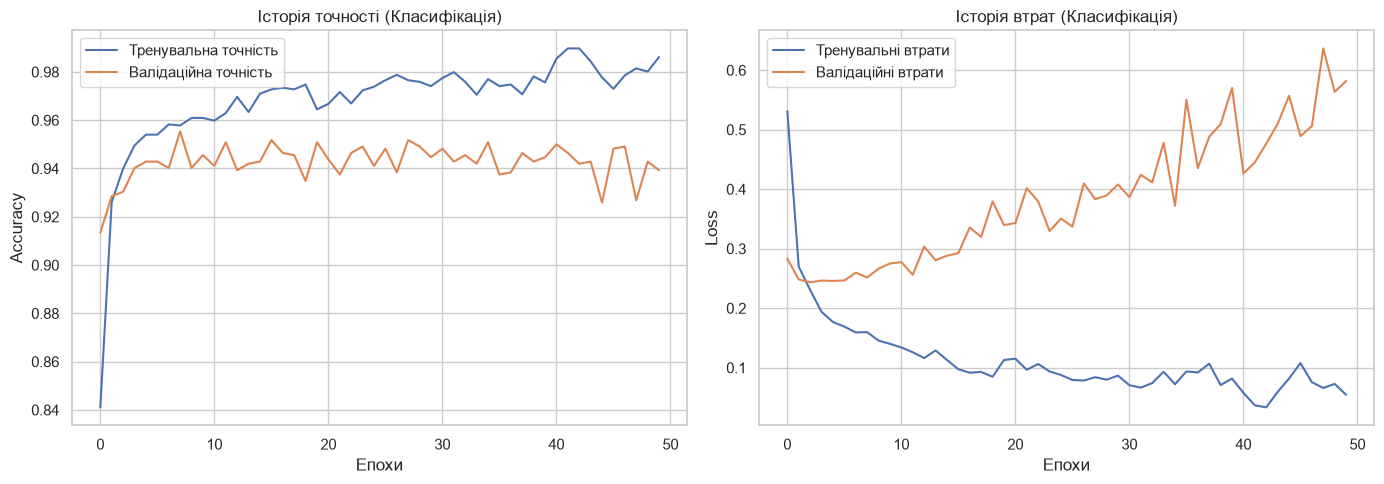

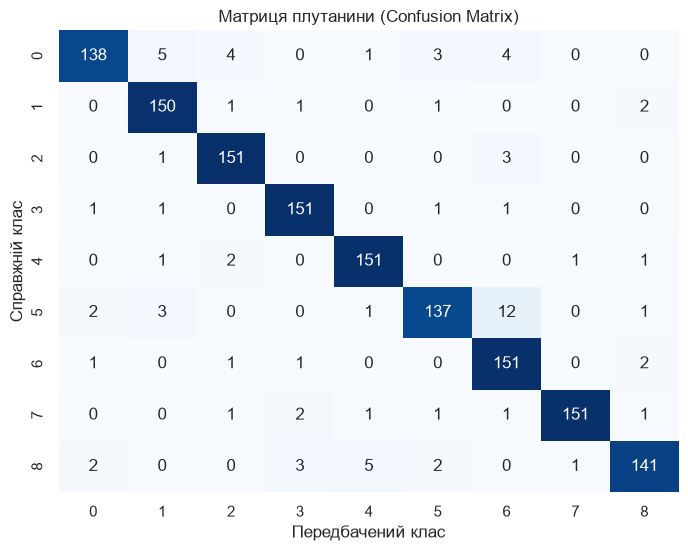

In [7]:
# Оцінка точності
y_pred_proba = model_clf.predict(X_test_clf_s, verbose=0)
y_pred_clf = np.argmax(y_pred_proba, axis=1)

accuracy = accuracy_score(y_test_clf, y_pred_clf)
print(f"Точність на тестовій вибірці (Accuracy): {accuracy:.4f}\n")
print("Класифікаційний звіт (Classification Report):")
print(classification_report(y_test_clf, y_pred_clf))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Графік точності (Accuracy)
axes[0].plot(history_clf.history['accuracy'], label='Тренувальна точність')
axes[0].plot(history_clf.history['val_accuracy'], label='Валідаційна точність')
axes[0].set_title('Історія точності (Класифікація)')
axes[0].set_xlabel('Епохи')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

# Графік втрат
axes[1].plot(history_clf.history['loss'], label='Тренувальні втрати')
axes[1].plot(history_clf.history['val_loss'], label='Валідаційні втрати')
axes[1].set_title('Історія втрат (Класифікація)')
axes[1].set_xlabel('Епохи')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

# Матриця плутанини (Confusion Matrix)
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test_clf, y_pred_clf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Матриця плутанини (Confusion Matrix)')
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.show()

# Загальні підсумки:

У ході виконання практичної роботи було успішно освоєно методи попередньої обробки даних, побудови та оцінки якості моделей машинного навчання (для задач регресії та класифікації).

Результати моделювання (для класифікації):

Під час порівняння кількох алгоритмів класифікації (логістична регресія, KNN, Random Forest, SVM) було встановлено, що ансамблеві методи (зокрема Random Forest) демонструють найвищу точність (Accuracy) та надійність завдяки стійкості до перенавчання.

Аналіз матриці плутанини (Confusion Matrix) та метрик (Precision, Recall, F1-Score) підтвердив, що модель здатна коректно розпізнавати основні класи з мінімальною кількістю хибнопозитивних помилок.

Результати моделювання (для регресії / нейромереж):

Побудовані повнозв'язні нейронні мережі за допомогою фреймворку TensorFlow/Keras показали високу ефективність в апроксимації даних.

Динаміка зміни функції втрат (Loss / MSE) свідчить про успішне навчання та збіжність моделі без ознак критичного перенавчання.

Практичне значення:

Набуто практичних навичок роботи з бібліотеками Python (scikit-learn, pandas, matplotlib, tensorflow), що дозволяє автоматизувати процес аналізу даних, підготовки ознак, візуалізації результатів та інтерпретації метрик для прийняття обґрунтованих рішень.